In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numerical_funcs import D2_mat, solve_newton
from test_funcs import analytical_profile

In [2]:
Nx = 200
x_start = 0
x_end = 4*np.pi
x = np.linspace(x_start, x_end, Nx)
y = np.sin(x) + 1/2 * x**3

/opt/miniconda3/envs/ptiii_proj/lib/python3.12/site-packages/scipy/sparse/_index.py:197: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


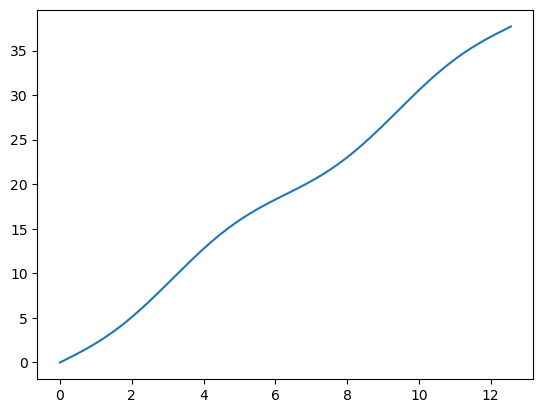

In [3]:
D2 = D2_mat(x)

d2ydx2 = D2 @ y

fig, ax = plt.subplots()
# ax.scatter(x, y)
ax.plot(x, d2ydx2)

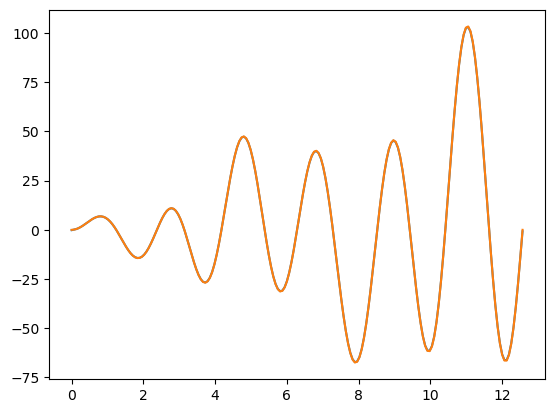

In [4]:
Nx = 200
x_start = 0
x_end = 4*np.pi
x = np.linspace(x_start, x_end, Nx)
y = np.sin(x) + 1/2 * x**3
h = np.sin(x)*np.ones(Nx)

exact = (16*np.sin(x)**4 - 12*np.sin(x)**2
         + 18*np.sin(x)**2*np.cos(x)
         + 18*x*np.sin(x)*np.cos(x)**2
         - 9*x*np.sin(x)**3)

d2ydx2 = D2 @ y
bend = D2 @ (h**3 * d2ydx2)
plt.plot(x, bend)
plt.plot(x, exact)

# Test Newton Raphson solver

In [5]:
# Analytical (Sayag/Worster case)
x_start = -10
x_end = 30
Nx = 200
x = np.linspace(x_start, x_end, Nx)
h = np.ones(Nx)
height_bb = 10/13 # H/L ratio
s_deg = 3 # bed slope in degrees
s = np.deg2rad(s_deg)
b0 = np.tan(s)* x / height_bb + 0.1*np.sin(x*np.pi/2)
kappa = 10**5
alpha = 917/1027
eps = 1e-8
zm0 = np.ones(Nx)
D2 = D2_mat(x)

zm = solve_newton(x, h, b0, zm0, kappa, alpha, eps, D2)

In [6]:
ya, ya_lower, ya_upper, xg = analytical_profile(x_start, x_end, Nx, h, height_bb, alpha, kappa, 3)
zm, lower, upper = solve_newton(x, h, b0, ya, kappa, alpha, eps, D2)

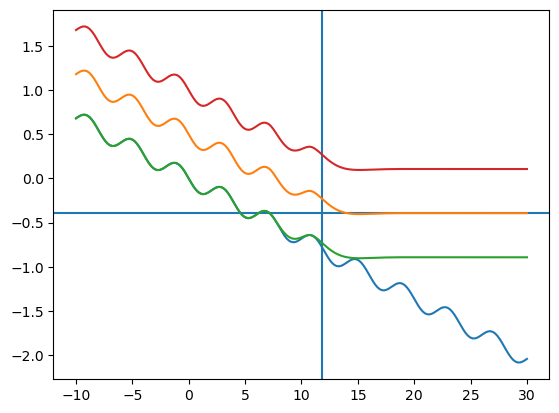

In [10]:
plt.plot(x, -b0)
plt.axhline((1/2 - alpha))
plt.axvline(xg)

# plt.plot(x, ya)
# plt.plot(x, ya_lower)
# plt.plot(x, ya_upper)
plt.plot(x, zm)
plt.plot(x, lower)
plt.plot(x, upper)

plt.show()


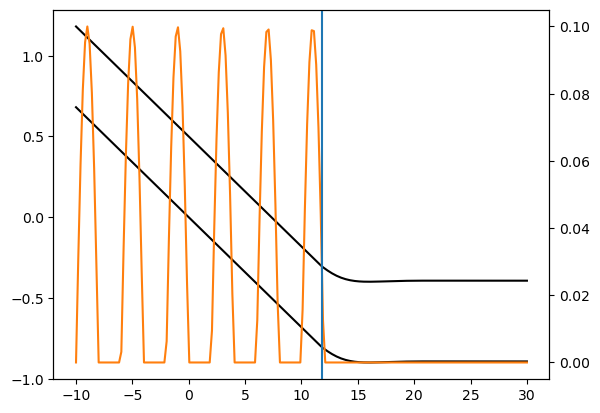

In [8]:
from scipy.special import expit
q1 = h/2 - ya - b0
q2 = h/2 - ya
S1 = expit(q1/eps)
S2 = expit(q2/eps)

fig, ax = plt.subplots()
ax.plot(x, ya, c='k')
ax.plot(x, ya_lower, c='k')
ax2 = ax.twinx()
ax2.plot(x, q1*S1, c='C1')
# ax2.plot(x, q2*S2, c='C2')
ax2.axvline(xg)
# ax2.plot(x, q1)
# ax.axhline(0)
# ax2.axvline(7.5)

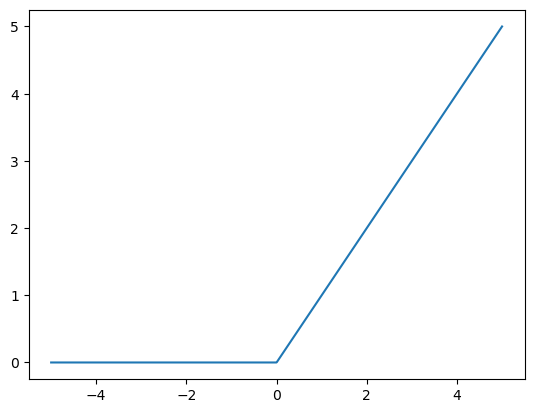

In [9]:
xlin = np.linspace(-5, 5, 1000)
plt.plot(xlin, xlin*expit(xlin/eps))